In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(7)

n = 400

ciudades    = ["Buenos Aires", "Córdoba", "Rosario", "Mendoza"]
tipos       = ["Departamento", "Casa", "PH"]

df = pd.DataFrame({
    "ciudad":       np.random.choice(ciudades, n, p=[0.45, 0.25, 0.20, 0.10]),
    "tipo":         np.random.choice(tipos,    n, p=[0.55, 0.30, 0.15]),
    "ambientes":    np.random.choice([1, 2, 3, 4, 5], n, p=[0.10, 0.30, 0.35, 0.20, 0.05]),
    "superficie_m2":np.random.normal(75, 25, n).clip(25, 200).round(1),
    "antiguedad":   np.random.exponential(15, n).clip(0, 60).round(0).astype(int),
    "precio_usd":   np.random.lognormal(11.5, 0.5, n).round(-3).astype(int),
    "expensas_ars": np.random.normal(45000, 15000, n).clip(5000, 120000).round(-3).astype(int),
})

# Agregar algunos valores atípicos intencionales
df.loc[5,  "precio_usd"]   = 850000
df.loc[12, "precio_usd"]   = 920000
df.loc[200,"expensas_ars"] = 180000

df.to_csv("propiedades.csv", index=False)
print(f"Dataset creado: {len(df)} filas")
print(df.describe())


Dataset creado: 400 filas
        ambientes  superficie_m2  antiguedad     precio_usd   expensas_ars
count  400.000000     400.000000  400.000000     400.000000     400.000000
mean     2.790000      75.946000   14.132500  109720.000000   46642.500000
std      1.033717      24.310252   13.615189   80674.453942   16516.406175
min      1.000000      25.000000    0.000000   22000.000000    5000.000000
25%      2.000000      58.375000    4.000000   67000.000000   37000.000000
50%      3.000000      76.800000   10.000000   93000.000000   47000.000000
75%      3.250000      93.900000   19.000000  125500.000000   57000.000000
max      5.000000     134.100000   60.000000  920000.000000  180000.000000


In [4]:
df = pd.read_csv("propiedades.csv")

In [5]:
df.shape

(400, 7)

In [5]:
media_precio = df["precio_usd"].mean()
print(f"Precio medio: ${media_precio:,.0f}")

Precio medio: $109,720


In [6]:
mediana_precio = df["precio_usd"].median()
print(f"Precio mediano: ${mediana_precio:,.0f}")

Precio mediano: $93,000


In [7]:
moda_ambientes = df["ambientes"].mode()[0]
moda_tipo      = df["tipo"].mode()[0]

print(f"Ambientes más frecuente: {moda_ambientes}")
print(f"Tipo más frecuente: {moda_tipo}")

Ambientes más frecuente: 3
Tipo más frecuente: Departamento


In [8]:
varianza_precio = df["precio_usd"].var()
print(f"Varianza del precio: {varianza_precio:,.0f}")

Varianza del precio: 6,508,367,519


In [9]:
std_precio = df["precio_usd"].std()
print(f"Desviación estándar del precio: ${std_precio:,.0f}")
print(f"Media: ${df['precio_usd'].mean():,.0f}")
print(f"Rango típico: ${df['precio_usd'].mean() - std_precio:,.0f} — ${df['precio_usd'].mean() + std_precio:,.0f}")

Desviación estándar del precio: $80,674
Media: $109,720
Rango típico: $29,046 — $190,394


In [11]:
df.describe().round(1)


,ambientes,superficie_m2,antiguedad,precio_usd,expensas_ars
count,400.0,400.0,400.0,400.0,400.0
mean,2.8,75.9,14.1,109720.0,46642.5
std,1.0,24.3,13.6,80674.5,16516.4
min,1.0,25.0,0.0,22000.0,5000.0
25%,2.0,58.4,4.0,67000.0,37000.0
50%,3.0,76.8,10.0,93000.0,47000.0
75%,3.2,93.9,19.0,125500.0,57000.0
max,5.0,134.1,60.0,920000.0,180000.0


In [13]:
p25 = df["precio_usd"].quantile(0.25)
p50 = df["precio_usd"].quantile(0.50)
p75 = df["precio_usd"].quantile(0.75)
p90 = df["precio_usd"].quantile(0.90)

print(f"P25: ${p25:,.0f}  — el 25% de las propiedades cuesta menos que esto")
print(f"P50: ${p50:,.0f}  — el 50% cuesta menos")
print(f"P75: ${p75:,.0f} — el 75% cuesta menos")
print(f"P90: ${p90:,.0f} — el 90% cuesta menos")


P25: $67,000  — el 25% de las propiedades cuesta menos que esto
P50: $93,000  — el 50% cuesta menos
P75: $125,500 — el 75% cuesta menos
P90: $177,200 — el 90% cuesta menos


In [6]:
correlacion = df[["precio_usd", "superficie_m2", "ambientes", "antiguedad", "expensas_ars"]].corr()
print(correlacion.round(2))


               precio_usd  superficie_m2  ambientes  antiguedad  expensas_ars
precio_usd           1.00           0.02      -0.06       -0.06         -0.00
superficie_m2        0.02           1.00      -0.08        0.06          0.02
ambientes           -0.06          -0.08       1.00       -0.11          0.04
antiguedad          -0.06           0.06      -0.11        1.00          0.02
expensas_ars        -0.00           0.02       0.04        0.02          1.00


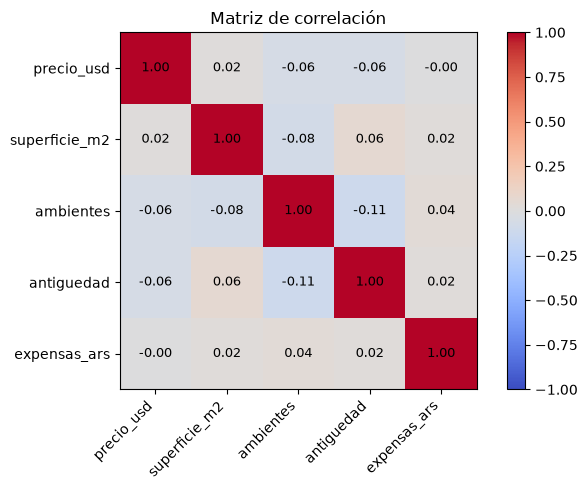

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))

correlacion_num = correlacion.values
columnas = correlacion.columns

im = ax.imshow(correlacion_num, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(im, ax=ax)

ax.set_xticks(range(len(columnas)))
ax.set_yticks(range(len(columnas)))
ax.set_xticklabels(columnas, rotation=45, ha="right")
ax.set_yticklabels(columnas)

for i in range(len(columnas)):
    for j in range(len(columnas)):
        ax.text(j, i, f"{correlacion_num[i, j]:.2f}",
                ha="center", va="center", fontsize=9)

ax.set_title("Matriz de correlación")
plt.tight_layout()
plt.show()


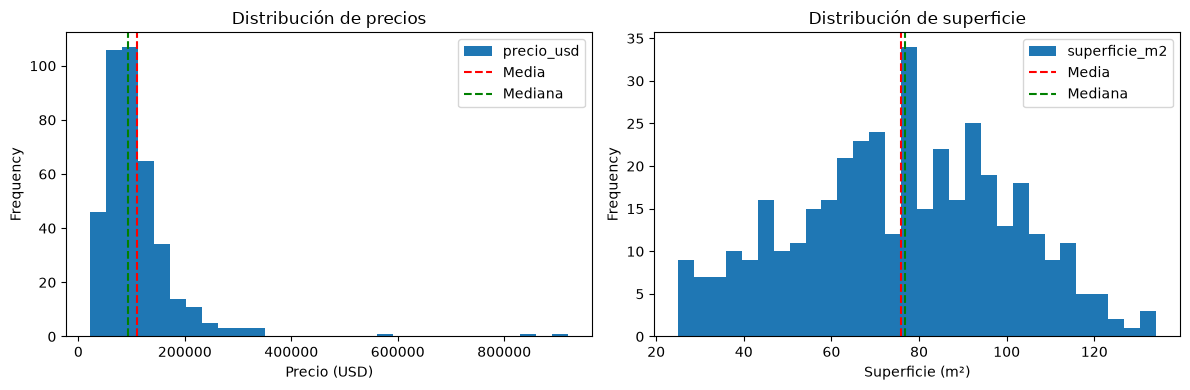

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df["precio_usd"].plot(kind="hist", bins=30, ax=axes[0], title="Distribución de precios")
axes[0].set_xlabel("Precio (USD)")
axes[0].axvline(df["precio_usd"].mean(),   color="red",   linestyle="--", label="Media")
axes[0].axvline(df["precio_usd"].median(), color="green", linestyle="--", label="Mediana")
axes[0].legend()

df["superficie_m2"].plot(kind="hist", bins=30, ax=axes[1], title="Distribución de superficie")
axes[1].set_xlabel("Superficie (m²)")
axes[1].axvline(df["superficie_m2"].mean(),   color="red",   linestyle="--", label="Media")
axes[1].axvline(df["superficie_m2"].median(), color="green", linestyle="--", label="Mediana")
axes[1].legend()

plt.tight_layout()
plt.show()
